<a href="https://colab.research.google.com/github/vidhis1612/Python/blob/main/MinorProject3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load dataset
df = pd.read_csv("diabetes.csv")


In [3]:
# Display dataset
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
# Inspect dimensions
df.shape

(768, 9)

In [6]:
# Inspect column names
df.columns.tolist()

['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age',
 'Outcome']

In [7]:
# Inspect data types
df.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [9]:
# Check missing values
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


DATA CLEANING

In [10]:
# Columns where zero is considered invalid
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

In [11]:
# Count invalid zero values
print("Invalid zeros before cleaning:")
print((df[zero_columns] == 0).sum())

Invalid zeros before cleaning:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [12]:
# Replace zeros with NaN
df_clean = df.copy()
df_clean[zero_columns] = df_clean[zero_columns].replace(0, np.nan)

In [14]:
# Check missing values after replacement
print("\nMissing values after replacement:")
print(df_clean.isnull().sum())

display(df_clean.head())


Missing values after replacement:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


TRAIN-TEST SPLIT

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
# Features (input variables)
X = df_clean.drop("Outcome", axis=1)

In [17]:
# Target variable
y = df_clean["Outcome"]

In [18]:
# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (614, 8)
Testing Features: (154, 8)

Training Target: (614,)
Testing Target: (154,)


MEDIAN IMPUTATION

In [19]:
from sklearn.impute import SimpleImputer

In [20]:
imputer = SimpleImputer(strategy="median")

In [21]:
# Fit on training data only
X_train_imputed = imputer.fit_transform(X_train)

In [22]:
# Apply to testing data
X_test_imputed = imputer.transform(X_test)

print("Missing values in training data:",
      np.isnan(X_train_imputed).sum())

print("Missing values in testing data:",
      np.isnan(X_test_imputed).sum())


Missing values in training data: 0
Missing values in testing data: 0


FEATURE SCALING

In [23]:
from sklearn.preprocessing import StandardScaler

In [24]:
scaler = StandardScaler()

In [25]:
# Fit on training data only
X_train_scaled = scaler.fit_transform(X_train_imputed)


In [26]:
# Transform testing data
X_test_scaled = scaler.transform(X_test_imputed)

print("Training data scaled successfully!")
print("Testing data scaled successfully!")

Training data scaled successfully!
Testing data scaled successfully!


LOGISTIC REGRESSION MODEL

In [27]:
from sklearn.linear_model import LogisticRegression

In [28]:
model = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)


In [29]:
# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [30]:
# Predict classes
y_pred = model.predict(X_test_scaled)

In [32]:
# Predict probabilities
y_prob = model.predict_proba(X_test_scaled)[:, 1]
print("\nFirst 10 predictions:")
print(y_pred[:10])


First 10 predictions:
[1 0 0 0 0 0 1 1 0 1]


MODEL EVALUATION

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("MODEL PERFORMANCE")

print(f"Accuracy: {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1 Score: {f1:.3f}")
print(f"ROC-AUC: {roc_auc:.3f}")

print("Classification Report:")
print(classification_report(y_test, y_pred))


MODEL PERFORMANCE
Accuracy: 0.734
Precision: 0.603
Recall: 0.704
F1 Score: 0.650
ROC-AUC: 0.813
Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154



CONFUSION MATRIX

In [34]:
from sklearn.metrics import confusion_matrix

In [35]:
cm = confusion_matrix(y_test, y_pred)

In [36]:
plt.figure(figsize=(7, 5))

<Figure size 700x500 with 0 Axes>

<Figure size 700x500 with 0 Axes>

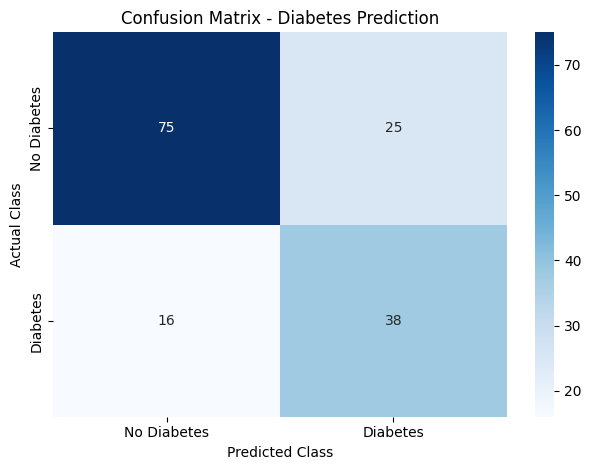

True Negatives: 75
False Positives: 25
False Negatives: 16
True Positives: 38


In [37]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.title("Confusion Matrix - Diabetes Prediction")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


ROC CURVE

In [38]:
from sklearn.metrics import roc_curve

In [39]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)


In [40]:
plt.figure(figsize=(8, 5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

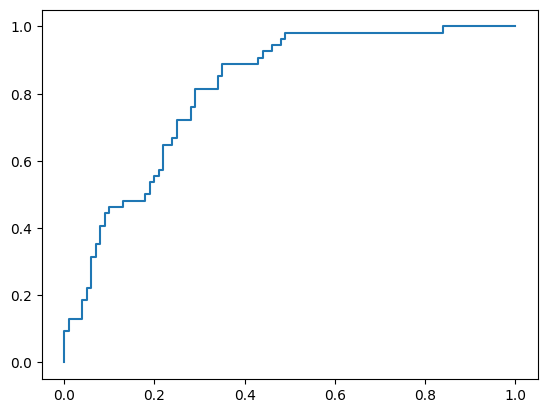

In [41]:
plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

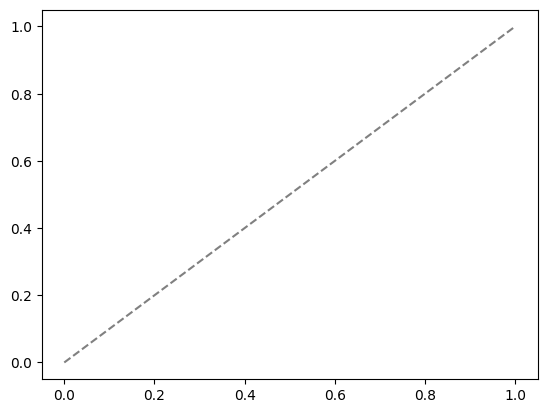

In [42]:
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

/tmp/ipykernel_3431/1847497457.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


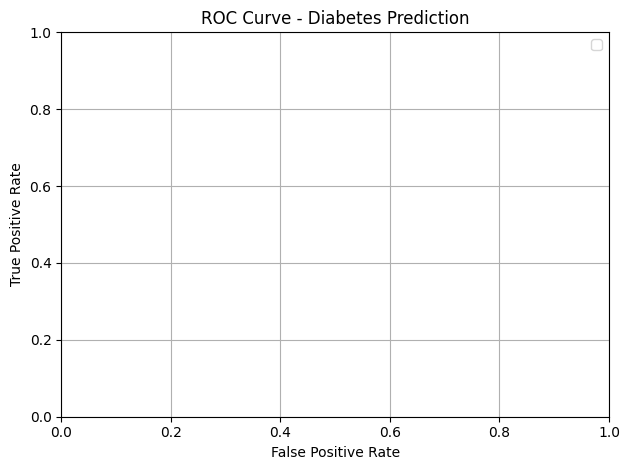

In [43]:
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Diabetes Prediction")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

MODEL COEFFICIENTS

In [44]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

In [45]:
coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

,Feature,Coefficient
1,Glucose,1.183483
5,BMI,0.709592
0,Pregnancies,0.372902
6,DiabetesPedigreeFunction,0.287734
7,Age,0.186434
3,SkinThickness,0.013980
2,BloodPressure,-0.014612
4,Insulin,-0.044609


<Axes: xlabel='Coefficient', ylabel='Feature'>

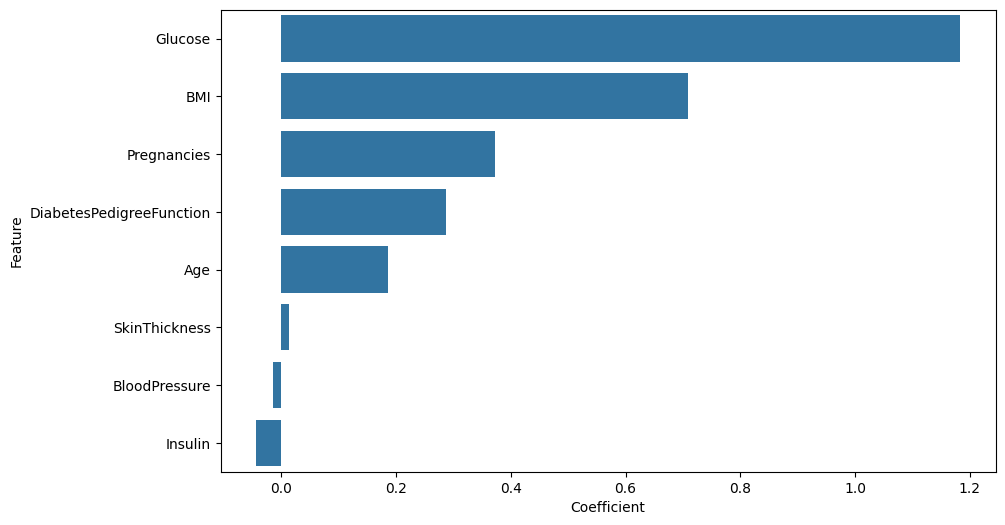

In [46]:
display(coefficients)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)

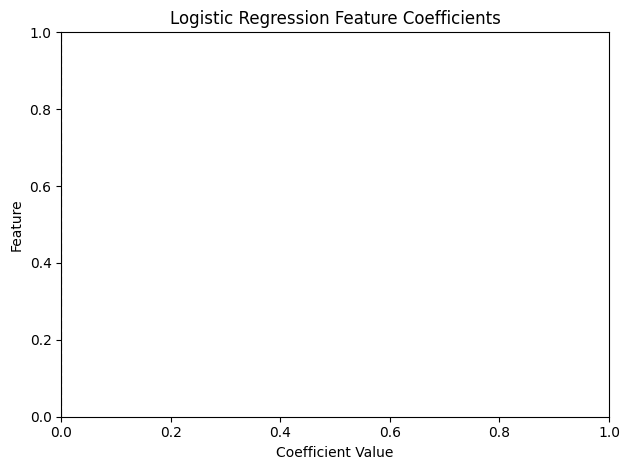

In [47]:
plt.title("Logistic Regression Feature Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")

plt.axvline(0, color="black", linestyle="--")
plt.tight_layout()
plt.show()